# LAB 3: FEATURE ENGINEERING

```text
==========================
Lecturer : Dr. Uzair Iqbal, Universiti Malaya (FSKTM)
Runs in : Google Colab or any Python 3.9+ with numpy, pandas, matplotlib, scikit-learn.

How to run
    Open this notebook in Google Colab and choose Runtime > Run all,
    or run the cells one at a time from top to bottom.

Learning objectives
    1. Profile a messy dataset: types, missing values, skew and outliers.
    2. Handle missing values, outliers and skewed variables.
    3. Encode categorical variables (one-hot, ordinal, frequency, target encoding).
    4. Scale numeric features and see when scaling matters.
    5. Create new features from dates, ratios, interactions and bins.
    6. Select features with filter, wrapper and embedded methods, and reduce
       dimensions with PCA.
    7. Build a leakage-free pipeline and prove the gain with cross-validation.

Data
    A synthetic customer churn dataset is generated in code, so no download is needed.
    It contains planted problems (missing values, outliers, rare categories, dates)
    and planted signal (a ratio, an interaction and a seasonal effect).
```

TASK 1: profile the data
         age       income         city      plan signup_date  usage_minutes  support_calls    noise1    noise2    noise3  churn
0  40.410313  1339.719769  KualaLumpur  standard  2022-11-02     652.793291              5 -0.076741 -0.452520 -0.428942      0
1  56.316970  5848.511073   Alor Setar   premium  2022-04-30     159.691969              3  0.125098  0.678155 -0.222471      0
2        NaN          NaN   Alor Setar     basic  2023-12-08     724.019970              2  0.731121 -0.443110 -0.130072      0
3  33.876315  4479.758477   JohorBahru     basic  2023-11-27     235.753426              4 -1.124151 -0.425310 -1.927623      0
4  36.424366  3232.487932      Kuching     basic  2022-12-08     442.179317              4  0.028743  0.060136  0.608892      0

Shape: (3000, 11) | churn rate: 0.327

Missing values (%):
age               8.0
income           12.0
city              5.0
plan              0.0
signup_date       0.0
usage_minutes     0.0
support_calls  

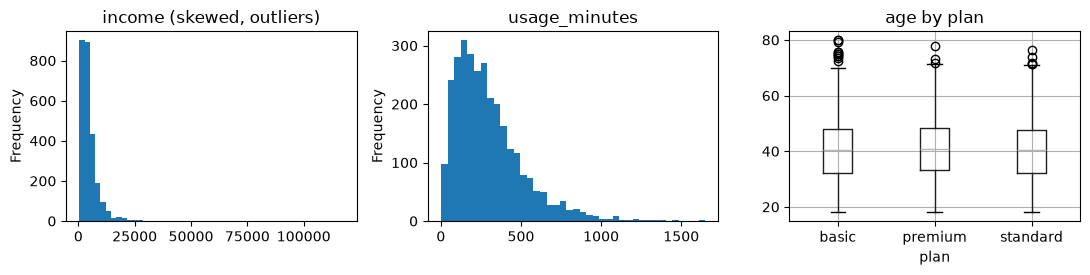

In [1]:
# Imports and data generation
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler,
                                   RobustScaler, KBinsDiscretizer, PolynomialFeatures,
                                   FunctionTransformer)
from sklearn.feature_selection import (VarianceThreshold, mutual_info_classif, RFE, SelectKBest)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (7, 3.6)
SEED = 11
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def make_data(n=3000, seed=SEED):
    rng = np.random.default_rng(seed)
    age = rng.normal(40, 12, n).clip(18, 80)
    income = np.exp(rng.normal(8.2, 0.7, n))                    # right skewed
    income[rng.choice(n, 15, replace=False)] *= 15               # extreme outliers
    city = rng.choice(["KualaLumpur", "Penang", "JohorBahru", "Ipoh", "Kuching", "Alor Setar",
                       "Seremban", "Miri", "Kuantan"], n,
                      p=[0.30, 0.18, 0.16, 0.10, 0.08, 0.06, 0.05, 0.04, 0.03])
    plan = rng.choice(["basic", "standard", "premium"], n, p=[0.5, 0.35, 0.15])
    signup = pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 1000, n), unit="D")
    usage = rng.gamma(2.0, 150, n)                               # minutes per month
    support_calls = rng.poisson(2.0, n)
    noise1, noise2, noise3 = rng.normal(size=(3, n))
    plan_num = pd.Series(plan).map({"basic": 0, "standard": 1, "premium": 2}).values
    month = signup.month.values
    tenure_days = (pd.Timestamp("2025-01-01") - signup).days.values

    # Planted signal: ratio, interaction, seasonality, non-linear age effect
    ratio = usage / (income / 1000)
    z_ratio = (np.log1p(ratio) - np.log1p(ratio).mean()) / np.log1p(ratio).std()
    z_tenure = (tenure_days - tenure_days.mean()) / tenure_days.std()
    logit = (-1.0
             + 0.5 * (support_calls - 2)
             + 1.0 * z_ratio                       # ratio of usage to income
             - 0.5 * plan_num
             + 1.6 * ((age < 28) & (plan_num == 0))   # interaction
             + 0.9 * np.isin(month, [11, 12, 1])      # seasonality
             - 0.5 * z_tenure
             + 1.3 * (city == "Kuching"))
    churn = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)

    df = pd.DataFrame({"age": age, "income": income, "city": city, "plan": plan,
                       "signup_date": signup, "usage_minutes": usage,
                       "support_calls": support_calls, "noise1": noise1,
                       "noise2": noise2, "noise3": noise3, "churn": churn})
    # Plant missing values
    df.loc[rng.choice(n, int(0.08 * n), replace=False), "age"] = np.nan
    df.loc[rng.choice(n, int(0.12 * n), replace=False), "income"] = np.nan
    df.loc[rng.choice(n, int(0.05 * n), replace=False), "city"] = np.nan
    return df


df = make_data()
y = df["churn"]
print("=" * 60)
print("TASK 1: profile the data")
print(df.head(5).to_string())
print("\nShape:", df.shape, "| churn rate:", round(y.mean(), 3))
print("\nMissing values (%):")
print((df.isna().mean() * 100).round(1).to_string())
print("\nSkewness of numeric columns:")
print(df.select_dtypes("number").drop(columns="churn").skew().round(2).to_string())
print("\nCity value counts:")
print(df["city"].value_counts(dropna=False).to_string())

fig, ax = plt.subplots(1, 3, figsize=(11, 3))
df["income"].dropna().plot.hist(bins=50, ax=ax[0], title="income (skewed, outliers)")
df["usage_minutes"].plot.hist(bins=40, ax=ax[1], title="usage_minutes")
df.boxplot(column="age", by="plan", ax=ax[2])
ax[2].set_title("age by plan")
plt.suptitle("")
plt.tight_layout()
plt.show()

In [2]:
# Helper: score a feature set with cross-validation, no leakage (all steps inside the pipeline)
def cv_score(model, X, y, scoring="roc_auc"):
    scores = cross_val_score(model, X, y, cv=CV, scoring=scoring)
    return scores.mean(), scores.std()


NUM_RAW = ["age", "income", "usage_minutes", "support_calls", "noise1", "noise2", "noise3"]
CAT_RAW = ["city", "plan"]

In [3]:
# Task 2: missing values
print("=" * 60)
print("TASK 2: missing value strategies (logistic regression, AUC, 5-fold CV)")
X_basic = df[NUM_RAW + CAT_RAW]


def make_pre(num_imputer, add_indicator=False):
    num = Pipeline([("imp", num_imputer), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUM_RAW), ("cat", cat, CAT_RAW)])


strategies = {
    "drop rows with missing values": None,
    "mean": SimpleImputer(strategy="mean"),
    "median": SimpleImputer(strategy="median"),
    "median + missing indicator": SimpleImputer(strategy="median", add_indicator=True),
    "KNN imputer (k=5)": KNNImputer(n_neighbors=5),
}
rows = []
for name, imp in strategies.items():
    if imp is None:
        d = df.dropna()
        m = Pipeline([("pre", make_pre(SimpleImputer(strategy="median"))),
                      ("clf", LogisticRegression(max_iter=1000))])
        mean, std = cv_score(m, d[NUM_RAW + CAT_RAW], d["churn"])
        rows.append({"strategy": name, "rows_used": len(d), "auc": mean, "std": std})
    else:
        m = Pipeline([("pre", make_pre(imp)), ("clf", LogisticRegression(max_iter=1000))])
        mean, std = cv_score(m, X_basic, y)
        rows.append({"strategy": name, "rows_used": len(df), "auc": mean, "std": std})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("Dropping rows loses data. Check whether imputation changes the score much here.")

TASK 2: missing value strategies (logistic regression, AUC, 5-fold CV)
                     strategy  rows_used    auc    std
drop rows with missing values       2304 0.7657 0.0093
                         mean       3000 0.7647 0.0256
                       median       3000 0.7653 0.0246
   median + missing indicator       3000 0.7648 0.0257
            KNN imputer (k=5)       3000 0.7637 0.0263
Dropping rows loses data. Check whether imputation changes the score much here.


TASK 3: outliers and skewed variables
IQR fences for income: -3288 to 11632 | outliers: 145
Skewness raw: 9.80 | clipped (winsorised): 1.01 | log1p: 0.22


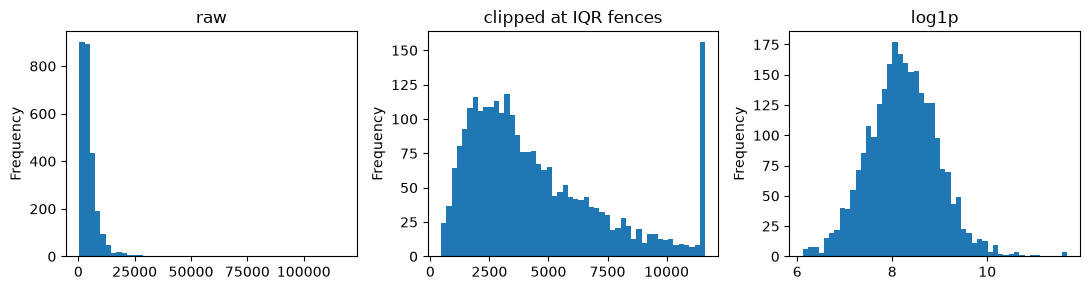


Sensitivity of scalers to outliers (value of a typical customer after scaling):
  Standard : -0.220
  MinMax   : 0.028
  Robust   : 0.000
MinMax squeezes typical values near 0 because outliers stretch the range.


In [4]:
# Task 3: outliers and skew
print("=" * 60)
print("TASK 3: outliers and skewed variables")
inc = df["income"].dropna()
q1, q3 = inc.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"IQR fences for income: {lo:.0f} to {hi:.0f} | outliers: {((inc < lo) | (inc > hi)).sum()}")
print(f"Skewness raw: {inc.skew():.2f} | clipped (winsorised): {inc.clip(lo, hi).skew():.2f} "
      f"| log1p: {np.log1p(inc).skew():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(11, 3))
inc.plot.hist(bins=50, ax=ax[0], title="raw")
inc.clip(lo, hi).plot.hist(bins=50, ax=ax[1], title="clipped at IQR fences")
np.log1p(inc).plot.hist(bins=50, ax=ax[2], title="log1p")
plt.tight_layout()
plt.show()

print("\nSensitivity of scalers to outliers (value of a typical customer after scaling):")
typical = inc.median()
for name, sc in [("Standard", StandardScaler()), ("MinMax", MinMaxScaler()), ("Robust", RobustScaler())]:
    sc.fit(inc.values.reshape(-1, 1))
    print(f"  {name:9s}: {sc.transform([[typical]])[0, 0]:.3f}")
print("MinMax squeezes typical values near 0 because outliers stretch the range.")

In [5]:
# Task 4: encoding categorical variables
print("=" * 60)
print("TASK 4: encoding categoricals")
cities = df["city"].fillna("Unknown")
print("One-hot columns for city:", cities.nunique())

freq = cities.map(cities.value_counts(normalize=True))
print("Frequency encoding example:\n", pd.DataFrame({"city": cities, "freq": freq}).drop_duplicates().head(5).to_string(index=False))

rare = cities.map(cities.value_counts()) < 100
print(f"Rare category grouping: {rare.sum()} rows would be grouped as 'Other'")


def oof_target_encode(train_col, train_y, n_splits=5, smooth=20, seed=SEED):
    """Leakage-safe target encoding: each row is encoded using statistics from OTHER folds."""
    enc = pd.Series(index=train_col.index, dtype=float)
    prior = train_y.mean()
    kf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr, va in kf.split(train_col, train_y):
        stats = train_y.iloc[tr].groupby(train_col.iloc[tr]).agg(["mean", "count"])
        smooth_mean = (stats["mean"] * stats["count"] + prior * smooth) / (stats["count"] + smooth)
        enc.iloc[va] = train_col.iloc[va].map(smooth_mean).fillna(prior).values
    full = train_y.groupby(train_col).agg(["mean", "count"])
    mapping = (full["mean"] * full["count"] + prior * smooth) / (full["count"] + smooth)
    return enc, mapping, prior


Xtr, Xte, ytr, yte = train_test_split(df, y, test_size=0.3, stratify=y, random_state=SEED)
c_tr, c_te = Xtr["city"].fillna("Unknown"), Xte["city"].fillna("Unknown")
enc_tr, mapping, prior = oof_target_encode(c_tr, ytr)
enc_te = c_te.map(mapping).fillna(prior)
print("\nTarget encoding (smoothed, out-of-fold) learned values:")
print(mapping.round(3).sort_values(ascending=False).to_string())
print("Naive target encoding on the training set would leak the label. Out-of-fold avoids this.")

print("\nEncoding comparison with a tree model (AUC on held-out 30%):")
for name, tr_feat, te_feat in [
    ("one-hot", pd.get_dummies(c_tr).astype(float), None),
    ("frequency", freq.loc[c_tr.index].to_frame("f"), None),
    ("target (out-of-fold)", enc_tr.to_frame("t"), enc_te.to_frame("t")),
]:
    if te_feat is None:
        if name == "one-hot":
            te_feat = pd.get_dummies(c_te).reindex(columns=tr_feat.columns, fill_value=0).astype(float)
        else:
            te_feat = c_te.map(cities.value_counts(normalize=True)).fillna(0).to_frame("f")
    rf = RandomForestClassifier(n_estimators=150, random_state=SEED, min_samples_leaf=5).fit(tr_feat, ytr)
    from sklearn.metrics import roc_auc_score
    print(f"  {name:22s} {roc_auc_score(yte, rf.predict_proba(te_feat)[:, 1]):.4f}")
print("city alone carries weak signal in this data, so expect small differences.")

TASK 4: encoding categoricals
One-hot columns for city: 10
Frequency encoding example:
        city     freq
KualaLumpur 0.298333
 Alor Setar 0.055333
 JohorBahru 0.138667
    Kuching 0.075000
       Ipoh 0.095667
Rare category grouping: 82 rows would be grouped as 'Other'

Target encoding (smoothed, out-of-fold) learned values:
city
Kuching        0.536
JohorBahru     0.358
Ipoh           0.330
Miri           0.325
Unknown        0.315
KualaLumpur    0.309
Alor Setar     0.290
Penang         0.285
Seremban       0.279
Kuantan        0.219
Naive target encoding on the training set would leak the label. Out-of-fold avoids this.

Encoding comparison with a tree model (AUC on held-out 30%):
  one-hot                0.5219
  frequency              0.5219
  target (out-of-fold)   0.5242
city alone carries weak signal in this data, so expect small differences.


In [6]:
# Task 5: scaling and distance based models
print("=" * 60)
print("TASK 5: why scaling matters for kNN")
numeric = df[["age", "income", "usage_minutes", "support_calls"]].fillna(df.median(numeric_only=True))
for name, model in [
    ("kNN without scaling", KNeighborsClassifier(15)),
    ("kNN + StandardScaler", Pipeline([("s", StandardScaler()), ("k", KNeighborsClassifier(15))])),
    ("kNN + RobustScaler", Pipeline([("s", RobustScaler()), ("k", KNeighborsClassifier(15))])),
    ("Random forest without scaling", RandomForestClassifier(150, random_state=SEED, min_samples_leaf=5)),
]:
    m, s = cv_score(model, numeric, y)
    print(f"  {name:32s} AUC = {m:.4f} (+/- {s:.4f})")
print("Distance based models need scaling. Tree models do not.")

TASK 5: why scaling matters for kNN
  kNN without scaling              AUC = 0.6387 (+/- 0.0155)
  kNN + StandardScaler             AUC = 0.6920 (+/- 0.0253)
  kNN + RobustScaler               AUC = 0.6935 (+/- 0.0296)
  Random forest without scaling    AUC = 0.7159 (+/- 0.0240)
Distance based models need scaling. Tree models do not.


In [7]:
# Task 6: creating new features
print("=" * 60)
print("TASK 6: feature construction (dates, ratios, interactions, bins)")


def add_features(d):
    d = d.copy()
    d["signup_month"] = d["signup_date"].dt.month
    d["signup_dow"] = d["signup_date"].dt.dayofweek
    d["tenure_days"] = (pd.Timestamp("2025-01-01") - d["signup_date"]).dt.days
    d["month_sin"] = np.sin(2 * np.pi * d["signup_month"] / 12)      # cyclic encoding
    d["month_cos"] = np.cos(2 * np.pi * d["signup_month"] / 12)
    d["winter_signup"] = d["signup_month"].isin([11, 12, 1]).astype(int)
    d["usage_per_income"] = d["usage_minutes"] / (d["income"] / 1000)
    d["log_income"] = np.log1p(d["income"])
    d["calls_per_year"] = d["support_calls"] / (d["tenure_days"] / 365 + 0.1)
    d["young_basic"] = ((d["age"] < 28) & (d["plan"] == "basic")).astype(int)
    d["income_missing"] = d["income"].isna().astype(int)
    d["age_missing"] = d["age"].isna().astype(int)
    return d


dfe = add_features(df)
new_cols = ["tenure_days", "month_sin", "month_cos", "winter_signup", "usage_per_income",
            "log_income", "calls_per_year", "young_basic", "income_missing", "age_missing"]
print(dfe[new_cols].describe().T[["mean", "std", "min", "max"]].round(2).to_string())

print("\nCorrelation of each engineered feature with churn:")
print(dfe[new_cols + ["churn"]].corr()["churn"].drop("churn").round(3).sort_values().to_string())

print("\nBinning age into 5 quantile bins and polynomial features:")
age_filled = df[["age"]].fillna(df["age"].median())
kb = KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile").fit(age_filled)
print("Bin edges:", np.round(kb.bin_edges_[0], 1))
poly = PolynomialFeatures(degree=2, include_bias=False).fit(numeric[["age", "support_calls"]])
print("Polynomial terms:", poly.get_feature_names_out(["age", "support_calls"]).tolist())

TASK 6: feature construction (dates, ratios, interactions, bins)
                    mean     std    min      max
tenure_days       592.69  288.80  97.00  1096.00
month_sin           0.03    0.72  -1.00     1.00
month_cos          -0.07    0.69  -1.00     1.00
winter_signup       0.21    0.41   0.00     1.00
usage_per_income  104.10  123.99   0.35  1264.76
log_income          8.22    0.73   6.12    11.68
calls_per_year      1.55    1.66   0.00    16.33
young_basic         0.08    0.27   0.00     1.00
income_missing      0.12    0.33   0.00     1.00
age_missing         0.08    0.27   0.00     1.00

Correlation of each engineered feature with churn:
log_income         -0.217
tenure_days        -0.153
month_sin          -0.057
income_missing     -0.012
age_missing         0.020
month_cos           0.083
winter_signup       0.102
young_basic         0.198
calls_per_year      0.227
usage_per_income    0.259

Binning age into 5 quantile bins and polynomial features:
Bin edges: [18.  30.7 38.

TASK 7: feature selection
Total features after encoding: 29
Filter 1, variance threshold removes: 0 features

Filter 2, top 8 by mutual information:
num__calls_per_year      0.0457
num__usage_per_income    0.0424
num__tenure_days         0.0305
num__support_calls       0.0293
num__income              0.0256
num__usage_minutes       0.0244
num__log_income          0.0198
cat__city_Kuantan        0.0180

Wrapper, RFE with logistic regression keeps:
['num__usage_minutes', 'num__support_calls', 'num__tenure_days', 'num__winter_signup', 'num__log_income', 'num__young_basic', 'cat__city_Kuching', 'cat__city_Seremban', 'cat__plan_basic', 'cat__plan_premium']

Embedded, L1 logistic regression non-zero coefficients: 14
cat__plan_premium     1.127
cat__city_Kuching     1.064
num__support_calls    0.634
num__log_income       0.556
num__usage_minutes    0.482
cat__plan_standard    0.467
num__tenure_days      0.428
num__young_basic      0.376

Permutation importance (random forest), top 8:
num__cal

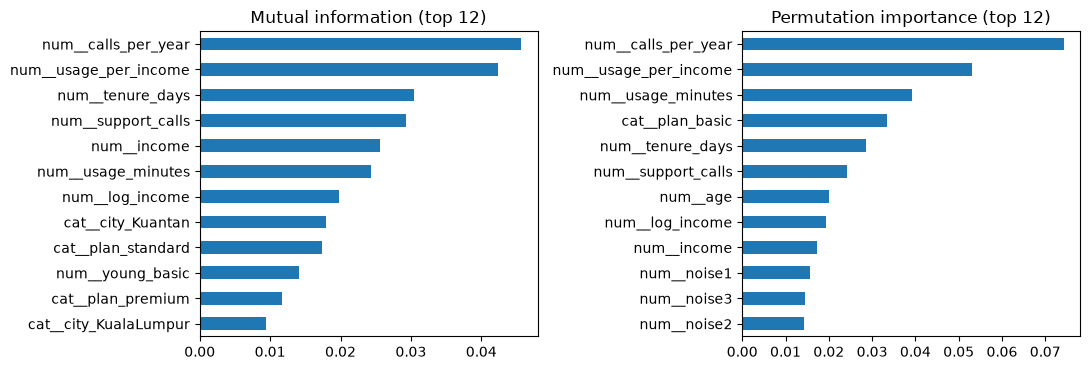


PCA on scaled numeric features
Components for 90% variance: 12 of 17


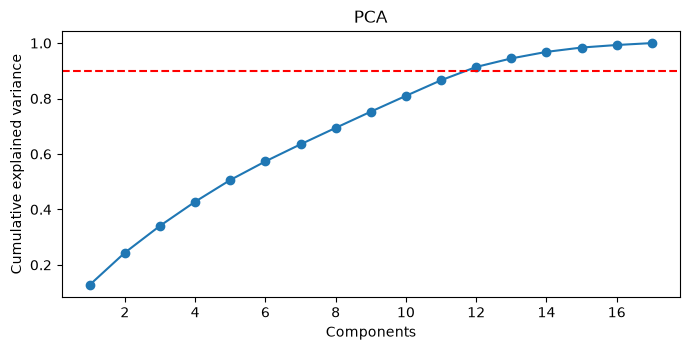

In [8]:
# Task 7: feature selection (filter, wrapper, embedded) and PCA
print("=" * 60)
print("TASK 7: feature selection")
ENG_NUM = ["age", "income", "usage_minutes", "support_calls", "noise1", "noise2", "noise3"] + new_cols
ENG_CAT = ["city", "plan"]


def make_full_pre(num_cols=ENG_NUM, cat_cols=ENG_CAT):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])


pre = make_full_pre().fit(dfe[ENG_NUM + ENG_CAT])
Xall = pre.transform(dfe[ENG_NUM + ENG_CAT])
names = pre.get_feature_names_out()
print("Total features after encoding:", Xall.shape[1])

vt = VarianceThreshold(threshold=0.01).fit(Xall)
print("Filter 1, variance threshold removes:", int((~vt.get_support()).sum()), "features")

mi = mutual_info_classif(Xall, y, random_state=SEED)
mi_s = pd.Series(mi, index=names).sort_values(ascending=False)
print("\nFilter 2, top 8 by mutual information:")
print(mi_s.head(8).round(4).to_string())

rfe = RFE(LogisticRegression(max_iter=2000), n_features_to_select=10).fit(Xall, y)
print("\nWrapper, RFE with logistic regression keeps:")
print(list(names[rfe.support_]))

l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.1).fit(Xall, y)
l1_s = pd.Series(np.abs(l1.coef_[0]), index=names).sort_values(ascending=False)
print("\nEmbedded, L1 logistic regression non-zero coefficients:", int((l1_s > 0).sum()))
print(l1_s.head(8).round(3).to_string())

rf = RandomForestClassifier(300, min_samples_leaf=5, random_state=SEED).fit(Xall, y)
perm = permutation_importance(rf, Xall, y, n_repeats=5, random_state=SEED, scoring="roc_auc")
perm_s = pd.Series(perm.importances_mean, index=names).sort_values(ascending=False)
print("\nPermutation importance (random forest), top 8:")
print(perm_s.head(8).round(4).to_string())
print("\nNoise features should rank low in every method:")
print(mi_s[[n for n in names if "noise" in n]].round(4).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
mi_s.head(12)[::-1].plot.barh(ax=ax[0], title="Mutual information (top 12)")
perm_s.head(12)[::-1].plot.barh(ax=ax[1], title="Permutation importance (top 12)")
plt.tight_layout()
plt.show()

print("\nPCA on scaled numeric features")
num_only = pre.named_transformers_["num"].transform(dfe[ENG_NUM])
pca = PCA().fit(num_only)
cum = np.cumsum(pca.explained_variance_ratio_)
print("Components for 90% variance:", int(np.argmax(cum >= 0.90)) + 1, "of", num_only.shape[1])
plt.figure()
plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.9, color="red", linestyle="--")
plt.xlabel("Components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA")
plt.tight_layout()
plt.show()

TASK 8: baseline vs engineered features (5-fold CV, everything fitted inside folds)
                 feature set        model    AUC    std
       Baseline raw features       LogReg 0.7653 0.0246
       Baseline raw features RandomForest 0.7688 0.0183
         Engineered features       LogReg 0.8045 0.0216
         Engineered features RandomForest 0.7911 0.0157
Engineered + top 12 selected       LogReg 0.7858 0.0236
Engineered + top 12 selected RandomForest 0.7747 0.0156


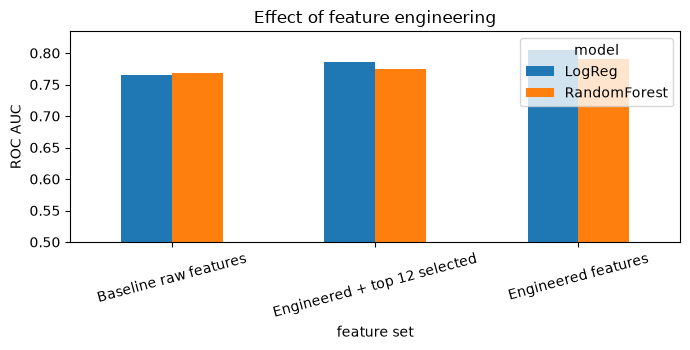

The engineered features should lift AUC, especially for the linear model,
because the ratio, seasonality and interaction were hidden in the raw columns.
Keeping only 12 features can lower AUC slightly: selection trades a little accuracy
for a simpler model. Discuss when that trade is worth making.


In [9]:
# Task 8: full leakage free pipeline and the final comparison
print("=" * 60)
print("TASK 8: baseline vs engineered features (5-fold CV, everything fitted inside folds)")

baseline_pre = make_pre(SimpleImputer(strategy="median"))
engineered_pre = make_full_pre()
selected_pre = Pipeline([("pre", make_full_pre()), ("sel", SelectKBest(mutual_info_classif, k=12))])

experiments = {
    "Baseline raw features": (baseline_pre, df[NUM_RAW + CAT_RAW]),
    "Engineered features": (engineered_pre, dfe[ENG_NUM + ENG_CAT]),
    "Engineered + top 12 selected": (selected_pre, dfe[ENG_NUM + ENG_CAT]),
}
rows = []
for exp, (pre_, X_) in experiments.items():
    for mname, clf in [("LogReg", LogisticRegression(max_iter=2000)),
                       ("RandomForest", RandomForestClassifier(200, min_samples_leaf=5, random_state=SEED))]:
        m, s = cv_score(Pipeline([("pre", pre_), ("clf", clf)]), X_, y)
        rows.append({"feature set": exp, "model": mname, "AUC": m, "std": s})
res = pd.DataFrame(rows)
print(res.round(4).to_string(index=False))

pivot = res.pivot(index="feature set", columns="model", values="AUC")
pivot.plot.bar(figsize=(7, 3.6), rot=15, ylim=(0.5, max(0.8, pivot.values.max() + 0.03)))
plt.ylabel("ROC AUC")
plt.title("Effect of feature engineering")
plt.tight_layout()
plt.show()
print("The engineered features should lift AUC, especially for the linear model,")
print("because the ratio, seasonality and interaction were hidden in the raw columns.")
print("Keeping only 12 features can lower AUC slightly: selection trades a little accuracy")
print("for a simpler model. Discuss when that trade is worth making.")

In [10]:
# Student exercises
"""
EXERCISES
1. Add a feature "is_premium_high_usage" and test whether it helps. Report the CV change.
2. Replace the manual out-of-fold target encoding with sklearn.preprocessing.TargetEncoder
   inside the ColumnTransformer and compare results.
3. Try PCA with 8 components inside the pipeline. When does it help or hurt?
4. Show a leakage example on purpose: scale the whole dataset before splitting and
   compare the CV score with the correct pipeline. Explain the difference.
5. Choose another dataset (for example sklearn fetch_openml "titanic") and repeat
   Tasks 1 to 8. Write a short report with your best features and evidence.
"""
print("Lab 3 finished.")

Lab 3 finished.
